# Case-Study: Wine Quality

Dāvis Eliass Mencis, ADS6.1, Claude Code -  Sonnet 4.6

In [4]:
import numpy as np # needed for numerical manipulation
import pandas as pd # To read and manipulate data
import os.path as osp # To access files in an OS agnostic way
from scipy import stats # needed to perform t-test
import matplotlib.pyplot as plt # To visualise data
from ucimlrepo import fetch_ucirepo # To fetch datasets from UCI repository
from sklearn.model_selection import train_test_split # to split the data 
from sklearn.linear_model import LinearRegression # for the regression model

## Problem Definition

In this assignment the problem is wine quality which affects the taste, acidity and alcohol of the wine. Predicting wine matters because it could save time for quality control and winemakers. In this experiment we will be trying to predict quality of wine. The dataset for research will be used from [this](https://archive.ics.uci.edu/dataset/186/wine+quality) URL. The research question guiding this experiment is: How do we predict the quality of wine?

## Data Acquisition

In [5]:
if osp.exists('../src/wine.json'):
    df = pd.read_json('../src/wine.json')
else:
    wine_quality = fetch_ucirepo(id=186)
    x = wine_quality.data.features
    y = wine_quality.data.targets

    # Combine into one dataframe and display it
    df = pd.concat([x, y, wine_quality.data.original['color']], axis=1)
    df.to_json('../src/wine.json')

In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 710.6 KB


In [7]:
# Display first 5 rows of the dataset
df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [8]:
# Display last 5 rows of the dataset
df.tail()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white
6496,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6,white


There are in total of 6497 rows and 13 columns in this data set. Data types which this data set includes are mostly float64 but there are also one int64 and str data type. There are no missing values in this given data set.

## Data Exploration

In [9]:
# Statistical exploration
df.describe()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [10]:
# Check number of missing values
df.isna().sum()

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64

In [11]:
# Check duplicates
df.duplicated().sum()

np.int64(1177)

From this statistical analysis we can make some observations. All of the variables have different value range. This can be an issue for advanced models which you would need to normalise the data but for now this is not an issue. Also as previously said there are no missing values in this data set. And to top it off, there are 1177 duplicate entries. In this case, duplicated values are around 18% of the data in this data set.

In [12]:
df['color'].value_counts(normalize=True)

color
white    0.753886
red      0.246114
Name: proportion, dtype: float64

From this observation we can say that this data set is not equaly fare. White wines are more than red ones.

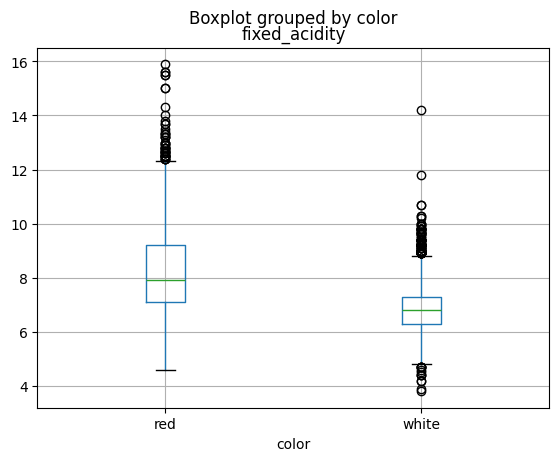

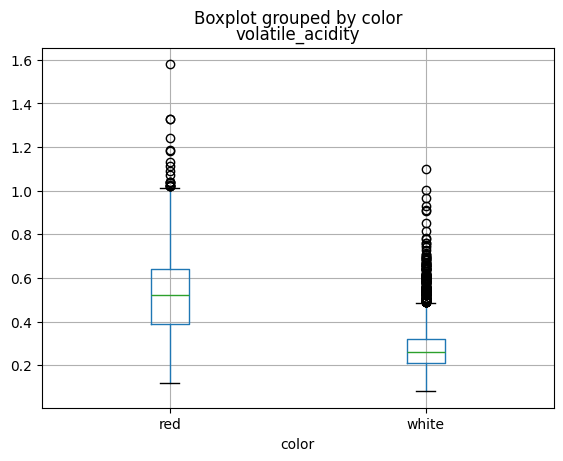

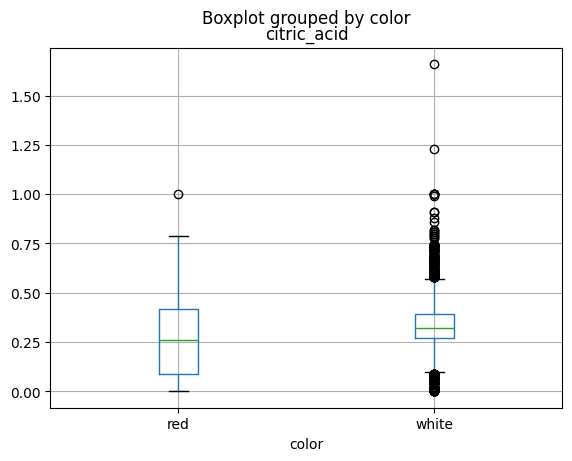

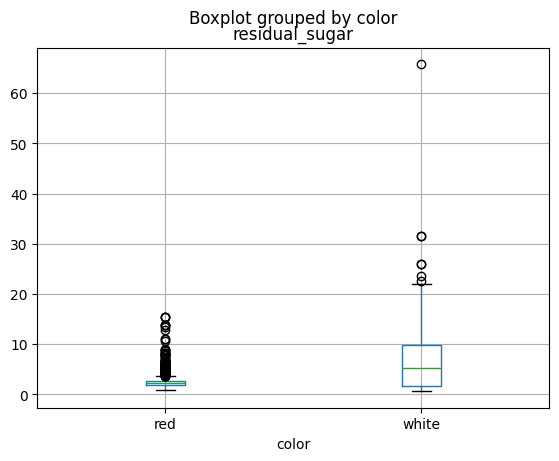

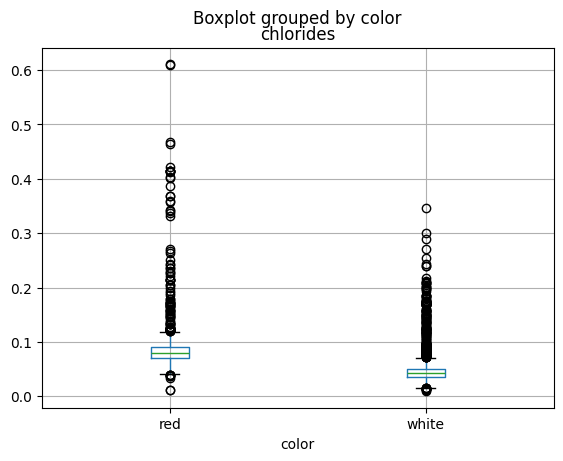

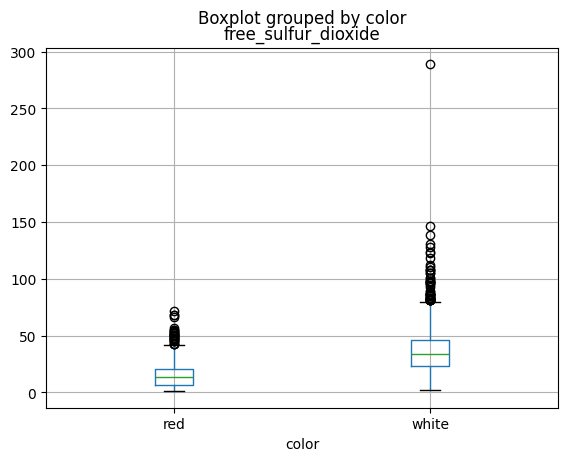

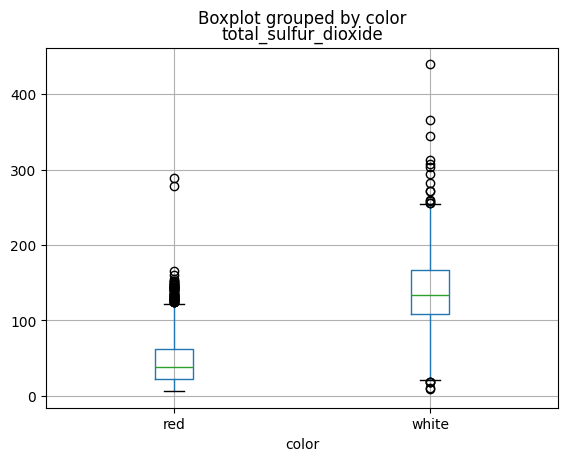

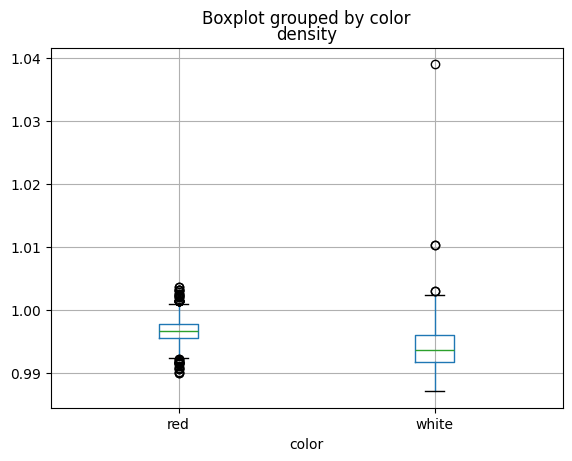

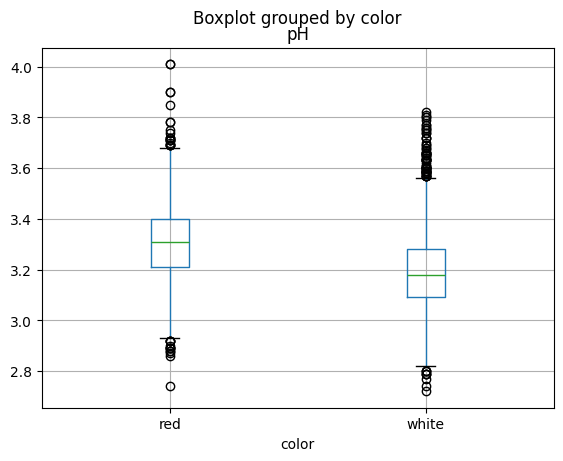

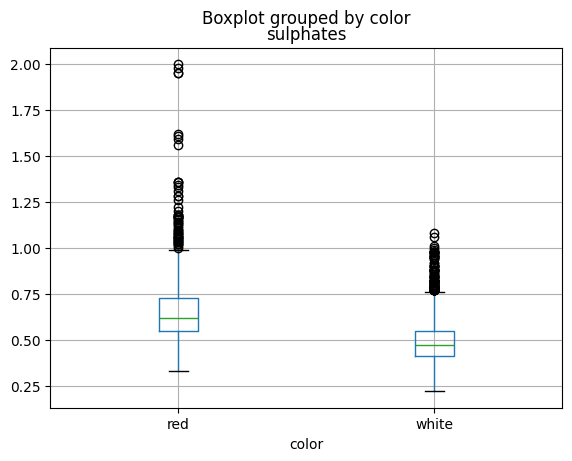

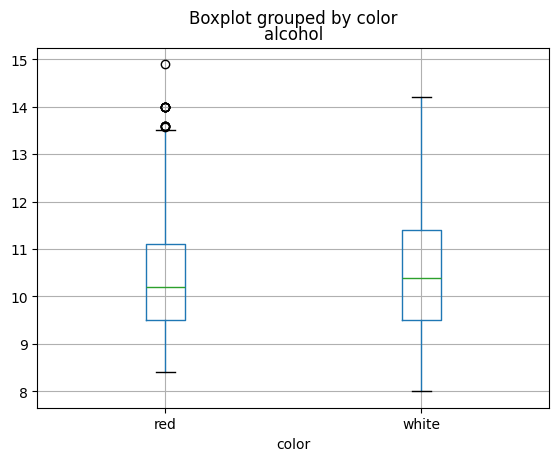

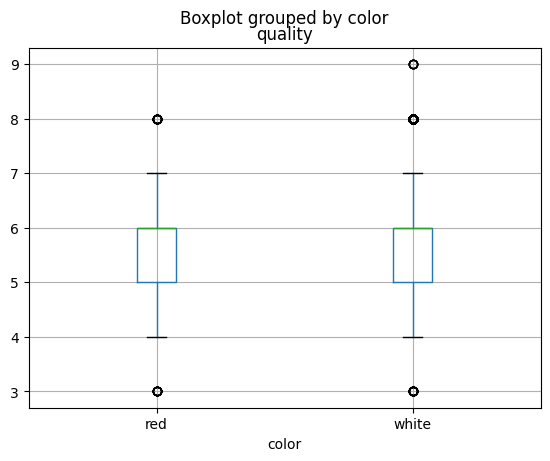

In [13]:
# Visual exploration

for col in df.select_dtypes(include='number').columns.to_list():
    df.boxplot(column=col, by='color')
    plt.show()

From these boxplots we look for presence of outliers. Several variables show notable outliers, particularly sulphates, pH, free_sulfur_dioxide, chlorides, residual_sugar, citric_acid, volatile_acidity, fixed_acidity. The outliers mean that there are some wines with high values for these properties. Further analysis would be needed to determine if these are errors or extreme cases.

From the alcohol boxplot we can say observe that it is the most equal comparing to other boxplots.

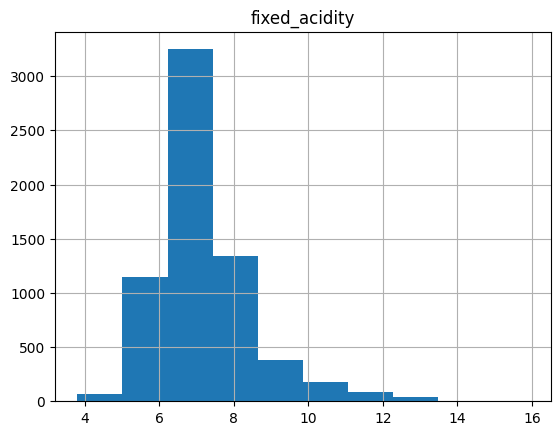

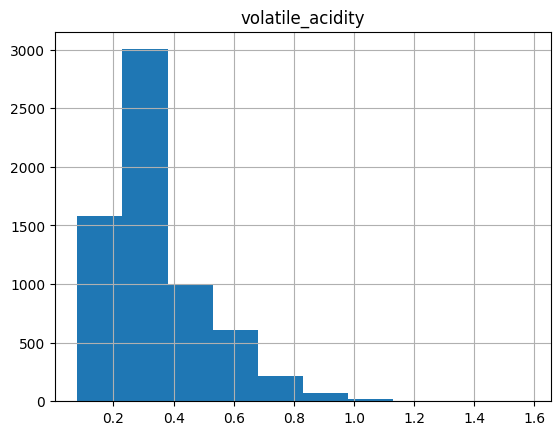

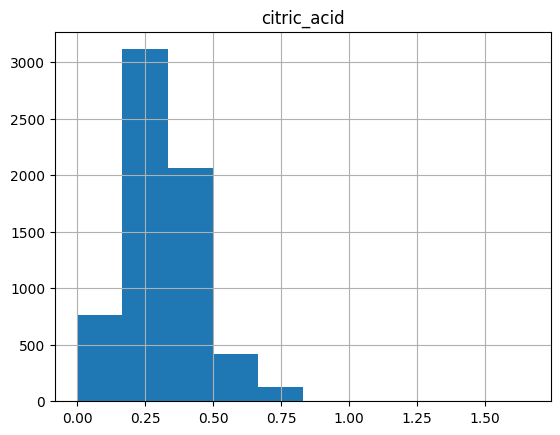

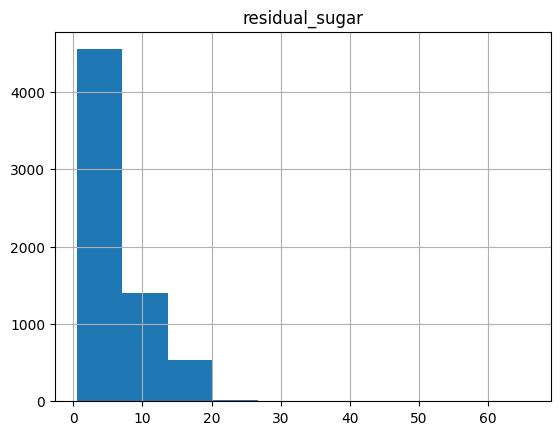

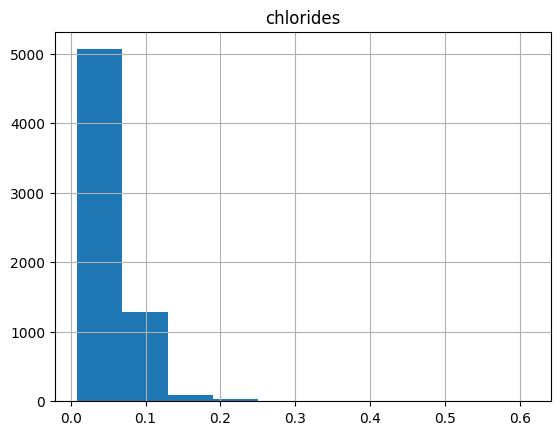

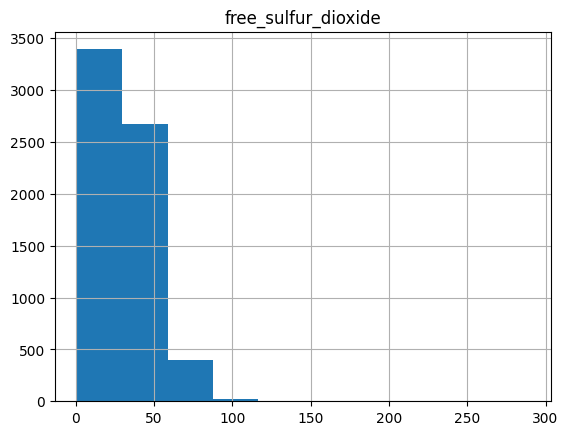

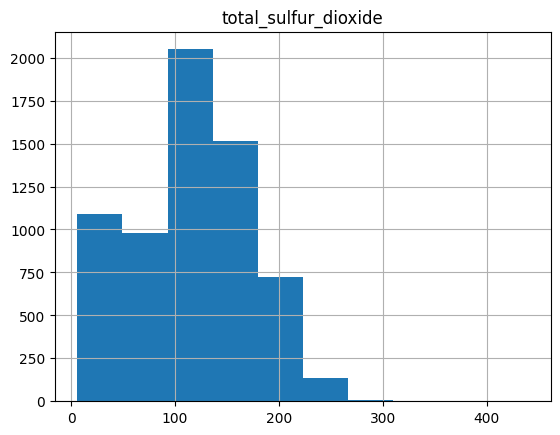

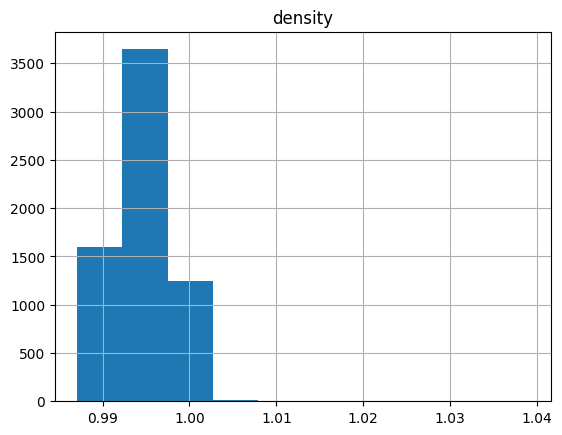

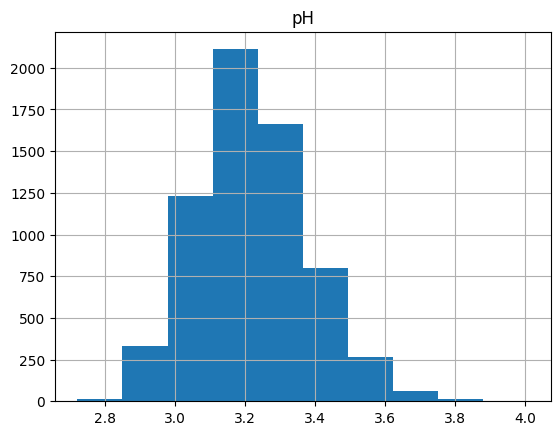

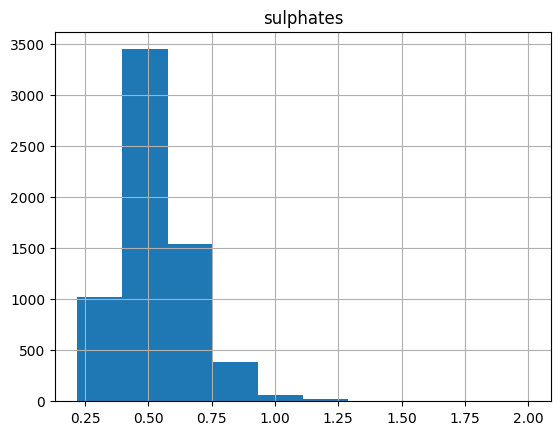

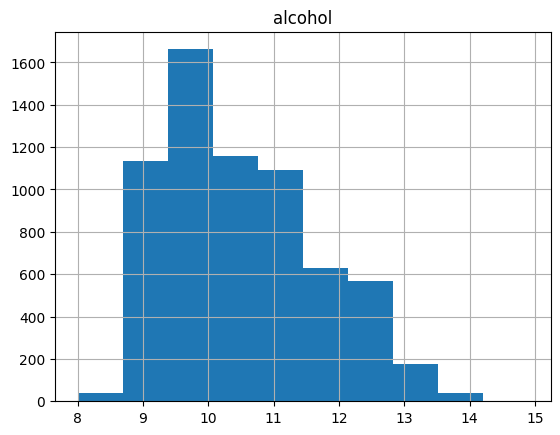

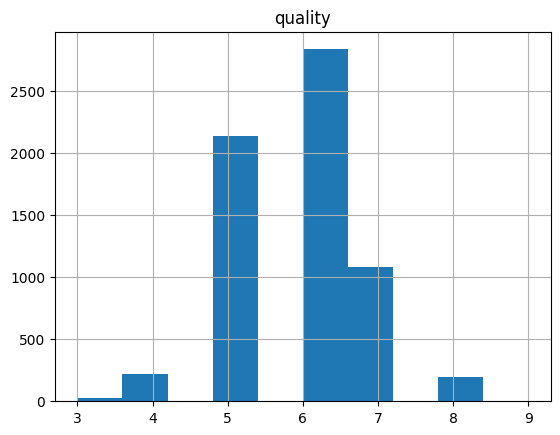

In [14]:
# Histograms
for col in df.select_dtypes(include='number').columns.to_list():
    df.hist(column=col)
    plt.show()

Looking on histograms, most of them are skewed to the right. That means most wines have low values for properties but a few wines have very high values. Looking at residual_sugar, chlorides, free_sufur_dioxide histograms, they are especially skewed to the right.

In [15]:
# Correlation analysis
corr = df.select_dtypes(include='number').corr()
corr

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
fixed_acidity,1.000000,0.219008,0.324436,-0.111981,0.298195,-0.282735,-0.329054,0.458910,-0.252700,0.299568,-0.095452,-0.076743
volatile_acidity,0.219008,1.000000,-0.377981,-0.196011,0.377124,-0.352557,-0.414476,0.271296,0.261454,0.225984,-0.037640,-0.265699
citric_acid,0.324436,-0.377981,1.000000,0.142451,0.038998,0.133126,0.195242,0.096154,-0.329808,0.056197,-0.010493,0.085532
residual_sugar,-0.111981,-0.196011,0.142451,1.000000,-0.128940,0.402871,0.495482,0.552517,-0.267320,-0.185927,-0.359415,-0.036980
chlorides,0.298195,0.377124,0.038998,-0.128940,1.000000,-0.195045,-0.279630,0.362615,0.044708,0.395593,-0.256916,-0.200666
free_sulfur_dioxide,-0.282735,-0.352557,0.133126,0.402871,-0.195045,1.000000,0.720934,0.025717,-0.145854,-0.188457,-0.179838,0.055463
total_sulfur_dioxide,-0.329054,-0.414476,0.195242,0.495482,-0.279630,0.720934,1.000000,0.032395,-0.238413,-0.275727,-0.265740,-0.041385
density,0.458910,0.271296,0.096154,0.552517,0.362615,0.025717,0.032395,1.000000,0.011686,0.259478,-0.686745,-0.305858
pH,-0.252700,0.261454,-0.329808,-0.267320,0.044708,-0.145854,-0.238413,0.011686,1.000000,0.192123,0.121248,0.019506
sulphates,0.299568,0.225984,0.056197,-0.185927,0.395593,-0.188457,-0.275727,0.259478,0.192123,1.000000,-0.003029,0.038485


From this correlation analysis we can observe that there is a moderate corrolation between quality and alchohol and density. Alcohol has positive correlation (0.444) but density has negative correlation (-0.306)

## Hypothesis testing

H0 - There is no difference in [variable] between red and white wine <br>
H1 - There is a difference in [variable] between red and white wine

In [16]:
red = df[df['color'] == 'red']

red

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,red
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,red
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,red
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,red


In [17]:
white = df[df['color'] == 'white']

white

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
1599,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6,white
1600,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6,white
1601,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6,white
1602,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6,white
1603,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6,white
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


In [18]:
alpha = 0.05

for col in df.select_dtypes(include='number').columns:
    t, p = stats.ttest_ind(red[col], white[col])
    if p <= alpha:
        print(f'{col}: Reject H0 - p={p:.4f}')
    else:
        print(f'{col}: Fail to reject H0 - p={p:.4f}')

fixed_acidity: Reject H0 - p=0.0000
volatile_acidity: Reject H0 - p=0.0000
citric_acid: Reject H0 - p=0.0000
residual_sugar: Reject H0 - p=0.0000
chlorides: Reject H0 - p=0.0000
free_sulfur_dioxide: Reject H0 - p=0.0000
total_sulfur_dioxide: Reject H0 - p=0.0000
density: Reject H0 - p=0.0000
pH: Reject H0 - p=0.0000
sulphates: Reject H0 - p=0.0000
alcohol: Reject H0 - p=0.0079
quality: Reject H0 - p=0.0000


We can observe that there is a statistically significant difference between red and white wine for every variable. The alcohol had the biggest p-value but this value is still significant. But we also have to keep in my that we have more information about white wine than red wine.

## Data Splitting

In [19]:
X = df.select_dtypes(include='number').drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(X_train.shape)
print(X_test.shape)

(4547, 11)
(1950, 11)


The dataset was split into training and test sets. 70% of the data (4547 rows) was used for training and 30% (1950 rows) for testing. This ensures the model is evaluated on unseen data.

## Regression

In [29]:
# 1st model - 11 variables

model1 = LinearRegression() # empty model
model1.fit(X_train, y_train) # model training

pd.DataFrame({'feature': X_train.columns, 'coefficient': model1.coef_}) # shows what model has learned  

,feature,coefficient
0,fixed_acidity,0.080087
1,volatile_acidity,-1.384834
2,citric_acid,-0.151579
3,residual_sugar,0.048813
4,chlorides,-0.057413
5,free_sulfur_dioxide,0.006955
6,total_sulfur_dioxide,-0.002660
7,density,-61.458115
8,pH,0.458414
9,sulphates,0.807036


We can observe that density is the biggest factor that negatively affects wine quality. However, pH, sulphates and alcohol are values that positively affects wine quality.

In [ ]:
# 2nd model - 2 variables

X_train2 = X_train[['alcohol', 'density']]
X_test2 = X_test[['alcohol', 'density']]

model2 = LinearRegression()
model2.fit(X_train2, y_train)

pd.DataFrame({'feature': X_train2.columns, 'coefficient': model2.coef_})

,feature,coefficient
0,alcohol,0.335922
1,density,4.067818


Alcohol and density were selected based on correlation analysis. Alcohol positively affects quality while density showed an unexpected positive coefficient (in correlation analysis it was -0.306) due to its strong interaction with alcohol.

In [30]:
# 3rd model - 1 variable

X_train3 = X_train[['alcohol']]
X_test3 = X_test[['alcohol']]

model3 = LinearRegression()
model3.fit(X_train3, y_train)

pd.DataFrame({'feature': X_train3.columns, 'coefficient': model3.coef_})

,feature,coefficient
0,alcohol,0.32891


Alcohol alone has a coefficient of ~0.33, meaning every 1 unit increase in alcohol increases predicted quality by ~0.33.

## Evaluation

## Observation & Interpretation